In [1]:
# ============================================================================
# CELL 1: Import Libraries
# ============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix
import joblib

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Set random seeds
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Device configuration
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda:0


In [2]:
# ============================================================================
# CELL 2: Load Config & Define Flattening Function (V6)
# ============================================================================
print("\n" + "="*80)
print("LOAD CONFIG & DEFINE FLATTENING FUNCTION (V6)")
print("="*80)

# Muat config untuk mendapatkan jumlah fitur
config = np.load('outputs/data/config.npy', allow_pickle=True).item()
TIMESTEP = config['timestep']
N_FEATURES_FRAUD = config['n_features_fraud']
N_FEATURES_OLIST = config['n_features_olist']

# Hitung jumlah fitur yang di-flatten (diratakan)
N_FEATURES_FRAUD_FLAT = N_FEATURES_FRAUD * TIMESTEP
N_FEATURES_OLIST_FLAT = N_FEATURES_OLIST * TIMESTEP

print(f"TIMESTEP: {TIMESTEP}")
print(f"Fitur flat Kaggle (V6): {N_FEATURES_FRAUD_FLAT} (={N_FEATURES_FRAUD} * {TIMESTEP})")
print(f"Fitur flat Olist (V6): {N_FEATURES_OLIST_FLAT} (={N_FEATURES_OLIST} * {TIMESTEP})")

def flatten_sequences_v6(X_seq):
    """
    Mengubah data dari (N, timestep, features) menjadi (N, timestep * features)
    Contoh: (1000, 2, 6) -> (1000, 12)
    """
    if X_seq.ndim != 3: 
        return X_seq # Sudah flat
    n_samples = X_seq.shape[0]
    n_timestep = X_seq.shape[1]
    n_features = X_seq.shape[2]
    # Reshape data
    return X_seq.reshape(n_samples, n_timestep * n_features)

print("✓ Fungsi 'flatten_sequences_v6' didefinisikan.")


LOAD CONFIG & DEFINE FLATTENING FUNCTION (V6)
TIMESTEP: 2
Fitur flat Kaggle (V6): 62 (=31 * 2)
Fitur flat Olist (V6): 12 (=6 * 2)
✓ Fungsi 'flatten_sequences_v6' didefinisikan.


In [3]:
# ============================================================================
# CELL 3: Load & Flatten Data (V6)
# ============================================================================
print("\n" + "="*80)
print("LOADING & FLATTENING SEQUENCES (Metode V6 - Adil)")
print("="*80)

# --- Flatten Fraud Dataset ---
print("Memuat & meratakan data Kaggle...")
# Muat data latih normal (digunakan untuk training IF/AE)
X_train_fraud_normal = np.load('outputs/data/X_train_fraud.npy')
X_train_fraud_flat = flatten_sequences_v6(X_train_fraud_normal)

# Muat data validasi
X_val_fraud = np.load('outputs/data/X_val_fraud.npy')
y_val_fraud = np.load('outputs/data/y_val_fraud.npy')
X_val_fraud_flat = flatten_sequences_v6(X_val_fraud)

print(f"FRAUD DATASET (FLATTENED V6):")
print(f"  Train Shape: {X_train_fraud_flat.shape}")
print(f"  Val Shape: {X_val_fraud_flat.shape}")

# --- Flatten Olist Dataset ---
print("\nMemuat & meratakan data Olist...")
# Muat data latih normal
X_train_olist_normal = np.load('outputs/data/X_train_olist.npy')
X_train_olist_flat = flatten_sequences_v6(X_train_olist_normal)

# Muat data validasi
X_val_olist = np.load('outputs/data/X_val_olist.npy')
y_val_olist = np.load('outputs/data/y_val_olist.npy')
X_val_olist_flat = flatten_sequences_v6(X_val_olist)

print(f"OLIST DATASET (FLATTENED V6):")
print(f"  Train Shape: {X_train_olist_flat.shape}")
print(f"  Val Shape: {X_val_olist_flat.shape}")


LOADING & FLATTENING SEQUENCES (Metode V6 - Adil)
Memuat & meratakan data Kaggle...
FRAUD DATASET (FLATTENED V6):
  Train Shape: (198982, 62)
  Val Shape: (42720, 62)

Memuat & meratakan data Olist...
OLIST DATASET (FLATTENED V6):
  Train Shape: (15205, 12)
  Val Shape: (3268, 12)


In [4]:
# ============================================================================
# CELL 4: Isolation Forest - Fraud Dataset
# ============================================================================
print("\n" + "="*80)
print("TRAINING ISOLATION FOREST - FRAUD DATASET")
print("="*80)

# Hitung kontaminasi HANYA untuk informasi
contamination_fraud = (y_val_fraud == 1).sum() / len(y_val_fraud)
print(f"Estimated contamination: {contamination_fraud:.6f}")

# Gunakan 'auto' atau nilai yang valid (<= 0.5)
contamination_setting_fraud = contamination_fraud if contamination_fraud > 0 and contamination_fraud <= 0.5 else 'auto'
print(f"Menggunakan contamination: {contamination_setting_fraud}")

iso_forest_fraud = IsolationForest(
    n_estimators=100,
    contamination=contamination_setting_fraud,
    random_state=42, 
    n_jobs=-1, 
    verbose=0
)

print("Training Isolation Forest (Fraud)...")
iso_forest_fraud.fit(X_train_fraud_flat)
joblib.dump(iso_forest_fraud, 'outputs/models/isolation_forest_fraud.pkl')
print("✓ Model IF (Fraud) saved!")


TRAINING ISOLATION FOREST - FRAUD DATASET
Estimated contamination: 0.001311
Menggunakan contamination: 0.0013108614232209739
Training Isolation Forest (Fraud)...
✓ Model IF (Fraud) saved!


In [5]:
# ============================================================================
# CELL 5: Isolation Forest - Olist Dataset
# ============================================================================
print("\n" + "="*80)
print("TRAINING ISOLATION FOREST - OLIST DATASET")
print("="*80)

# Hitung kontaminasi
contamination_olist = (y_val_olist == 1).sum() / len(y_val_olist)
print(f"Estimated contamination: {contamination_olist:.6f}")

# Gunakan 'auto' atau nilai yang valid (<= 0.5)
contamination_setting_olist = contamination_olist if contamination_olist > 0 and contamination_olist <= 0.5 else 'auto'
print(f"Menggunakan contamination: {contamination_setting_olist}")

iso_forest_olist = IsolationForest(
    n_estimators=100,
    contamination=contamination_setting_olist,
    random_state=42, 
    n_jobs=-1, 
    verbose=0
)

print("Training Isolation Forest (Olist)...")
iso_forest_olist.fit(X_train_olist_flat)
joblib.dump(iso_forest_olist, 'outputs/models/isolation_forest_olist.pkl')
print("✓ Model IF (Olist) saved!")


TRAINING ISOLATION FOREST - OLIST DATASET
Estimated contamination: 0.199204
Menggunakan contamination: 0.1992044063647491
Training Isolation Forest (Olist)...
✓ Model IF (Olist) saved!


In [6]:
# ============================================================================
# CELL 6: Define Standard Autoencoder (V6)
# ============================================================================
print("\n" + "="*80)
print("DEFINING STANDARD AUTOENCODER ARCHITECTURE (V6)")
print("="*80)
# (Variabel N_FEATURES_..._FLAT sudah didefinisikan di CELL 2)

class StandardAutoencoder(nn.Module):
    def __init__(self, n_features, hidden_dim1=64, hidden_dim2=32, latent_dim=16, dropout=0.2):
        super(StandardAutoencoder, self).__init__()
        
        self.n_features = n_features
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(n_features, hidden_dim1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim1, hidden_dim2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim2, latent_dim),
            nn.ReLU()
        )
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim2, hidden_dim1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim1, n_features)
        )
        
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

print("✓ Standard Autoencoder class (V6) defined!")


DEFINING STANDARD AUTOENCODER ARCHITECTURE (V6)
✓ Standard Autoencoder class (V6) defined!


In [7]:
# ============================================================================
# CELL 7: Define Training Function (Standard AE)
# ============================================================================
print("\n" + "="*80)
print("DEFINING TRAINING FUNCTION FOR STANDARD AE")
print("="*80)

def train_standard_ae(model, train_loader, val_loader, criterion, optimizer, 
                      num_epochs, device, model_name='model'):
    """
    Fungsi pelatihan untuk Standard Autoencoder (data flat).
    """
    train_losses, val_losses = [], []
    best_val_loss = float('inf')
    patience, patience_counter = 10, 0
    
    print(f"\nTraining {model_name}...")
    
    # Cek jika loader kosong (penting untuk V-SINTA1)
    if not train_loader or len(train_loader.dataset) == 0:
        print("Error: Train loader kosong. Tidak bisa melatih model.")
        return [], []
        
    if not val_loader or len(val_loader.dataset) == 0:
        print("Warning: Validation loader kosong. Melanjutkan tanpa validasi.")
        
    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for batch_data in train_loader:
            if not batch_data: continue
            inputs = batch_data[0].to(device)
            outputs = model(inputs)
            loss = criterion(outputs, inputs)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        
        avg_train_loss = train_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        
        model.eval()
        val_loss = 0.0
        if val_loader and len(val_loader.dataset) > 0:
            with torch.no_grad():
                for batch_data in val_loader:
                    if not batch_data: continue
                    inputs = batch_data[0].to(device)
                    outputs = model(inputs)
                    loss = criterion(outputs, inputs)
                    val_loss += loss.item()
            avg_val_loss = val_loss / len(val_loader)
        else:
            avg_val_loss = 0.0 # Tidak ada validasi
            
        val_losses.append(avg_val_loss)
        
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:<5} Train Loss: {avg_train_loss:<.6f} Val Loss: {avg_val_loss:<.6f}")
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
            torch.save({'model_state_dict': model.state_dict()}, f'outputs/models/{model_name}_best.pth')
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered at epoch {epoch + 1}")
                break
                
    print(f"Training completed! Best validation loss: {best_val_loss:.6f}")
    return train_losses, val_losses

print("✓ Training function defined!")


DEFINING TRAINING FUNCTION FOR STANDARD AE
✓ Training function defined!


In [8]:
# ============================================================================
# CELL 8: Train Standard AE - Fraud Dataset (V6)
# ============================================================================
print("\n" + "="*80)
print("TRAINING STANDARD AUTOENCODER - FRAUD DATASET (V6)")
print("="*80)

# Set hyperparameters
BATCH_SIZE = 256
LEARNING_RATE = 0.001
NUM_EPOCHS = 100

# Buat DataLoaders
train_dataset = TensorDataset(torch.FloatTensor(X_train_fraud_flat))
val_dataset = TensorDataset(torch.FloatTensor(X_val_fraud_flat))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Inisialisasi model dengan jumlah fitur V6 (flat)
model_ae_fraud = StandardAutoencoder(
    n_features=N_FEATURES_FRAUD_FLAT,
    hidden_dim1=64, 
    hidden_dim2=32, 
    latent_dim=16
).to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model_ae_fraud.parameters(), lr=LEARNING_RATE)

# Latih model
train_losses_ae_fraud, val_losses_ae_fraud = train_standard_ae(
    model_ae_fraud, train_loader, val_loader, criterion, optimizer,
    NUM_EPOCHS, device, 'standard_ae_fraud'
)


TRAINING STANDARD AUTOENCODER - FRAUD DATASET (V6)

Training standard_ae_fraud...
Epoch 1     Train Loss: 0.827418 Val Loss: 0.909474
Epoch 5     Train Loss: 0.694830 Val Loss: 0.800446
Epoch 10    Train Loss: 0.664433 Val Loss: 0.750534
Epoch 15    Train Loss: 0.653409 Val Loss: 0.743754
Epoch 20    Train Loss: 0.647932 Val Loss: 0.747520
Epoch 25    Train Loss: 0.644473 Val Loss: 0.739749
Epoch 30    Train Loss: 0.641497 Val Loss: 0.727516
Epoch 35    Train Loss: 0.636093 Val Loss: 0.712663
Epoch 40    Train Loss: 0.633071 Val Loss: 0.699801
Epoch 45    Train Loss: 0.630598 Val Loss: 0.703286
Epoch 50    Train Loss: 0.627838 Val Loss: 0.688769
Epoch 55    Train Loss: 0.629023 Val Loss: 0.684570
Epoch 60    Train Loss: 0.623679 Val Loss: 0.685432
Epoch 65    Train Loss: 0.625137 Val Loss: 0.695939
Epoch 70    Train Loss: 0.622239 Val Loss: 0.678575
Epoch 75    Train Loss: 0.620542 Val Loss: 0.693908
Epoch 80    Train Loss: 0.620949 Val Loss: 0.683308
Epoch 85    Train Loss: 0.620101 

In [9]:
# ============================================================================
# CELL 9: Train Standard AE - Olist Dataset (V6)
# ============================================================================
print("\n" + "="*80)
print("TRAINING STANDARD AUTOENCODER - OLIST DATASET (V6)")
print("="*80)

# Buat DataLoaders
train_dataset = TensorDataset(torch.FloatTensor(X_train_olist_flat))
val_dataset = TensorDataset(torch.FloatTensor(X_val_olist_flat))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Arsitektur lebih kecil untuk fitur 12 (6 fitur * 2 timestep)
model_ae_olist = StandardAutoencoder(
    n_features=N_FEATURES_OLIST_FLAT,
    hidden_dim1=10, 
    hidden_dim2=4, 
    latent_dim=2 
).to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model_ae_olist.parameters(), lr=LEARNING_RATE)

# Latih model
train_losses_ae_olist, val_losses_ae_olist = train_standard_ae(
    model_ae_olist, train_loader, val_loader, criterion, optimizer,
    NUM_EPOCHS, device, 'standard_ae_olist'
)


TRAINING STANDARD AUTOENCODER - OLIST DATASET (V6)

Training standard_ae_olist...
Epoch 1     Train Loss: 1.042577 Val Loss: 2.759087
Epoch 5     Train Loss: 0.940935 Val Loss: 2.620456
Epoch 10    Train Loss: 0.864047 Val Loss: 2.397229
Epoch 15    Train Loss: 0.843557 Val Loss: 2.359807
Epoch 20    Train Loss: 0.829213 Val Loss: 2.153300
Epoch 25    Train Loss: 0.813697 Val Loss: 1.763132
Epoch 30    Train Loss: 0.802679 Val Loss: 1.641530
Epoch 35    Train Loss: 0.802273 Val Loss: 1.639728
Epoch 40    Train Loss: 0.798199 Val Loss: 1.628416
Epoch 45    Train Loss: 0.797183 Val Loss: 1.631845
Epoch 50    Train Loss: 0.801033 Val Loss: 1.592250
Epoch 55    Train Loss: 0.785445 Val Loss: 1.551917
Epoch 60    Train Loss: 0.790931 Val Loss: 1.529326
Epoch 65    Train Loss: 0.794338 Val Loss: 1.546490
Epoch 70    Train Loss: 0.789903 Val Loss: 1.567196
Epoch 75    Train Loss: 0.783849 Val Loss: 1.542035
Epoch 80    Train Loss: 0.782928 Val Loss: 1.580781
Epoch 85    Train Loss: 0.790336 

In [10]:
# ============================================================================
# CELL 10: Summary
# ============================================================================
print("\n" + "="*80)
print("BASELINE MODELS TRAINING SUMMARY (V-SINTA1)")
print("="*80)

summary_data = {
    'Model': ['IF - Fraud', 'Standard AE - Fraud', 'IF - Olist', 'Standard AE - Olist'],
    'Type': ['Static-V6 (Flat)', 'Static-V6 (Flat)', 'Static-V6 (Flat)', 'Static-V6 (Flat)'],
    'Input Shape': [X_train_fraud_flat.shape, X_train_fraud_flat.shape,
                    X_train_olist_flat.shape, X_train_olist_flat.shape],
    'Threshold': ['Auto', 'Calculated in N5', 'Auto', 'Calculated in N5']
}
df_summary = pd.DataFrame(summary_data)
print("\n", df_summary.to_string(index=False))

print("\n" + "="*80)
print("BASELINE MODELS TRAINING COMPLETED!")
print("="*80)
print("\nNext steps:")
print("1. Run Notebook 5 for comprehensive evaluation")


BASELINE MODELS TRAINING SUMMARY (V-SINTA1)

               Model             Type  Input Shape        Threshold
         IF - Fraud Static-V6 (Flat) (198982, 62)             Auto
Standard AE - Fraud Static-V6 (Flat) (198982, 62) Calculated in N5
         IF - Olist Static-V6 (Flat)  (15205, 12)             Auto
Standard AE - Olist Static-V6 (Flat)  (15205, 12) Calculated in N5

BASELINE MODELS TRAINING COMPLETED!

Next steps:
1. Run Notebook 5 for comprehensive evaluation



PLOTTING TRAINING HISTORY - STANDARD AE OLIST


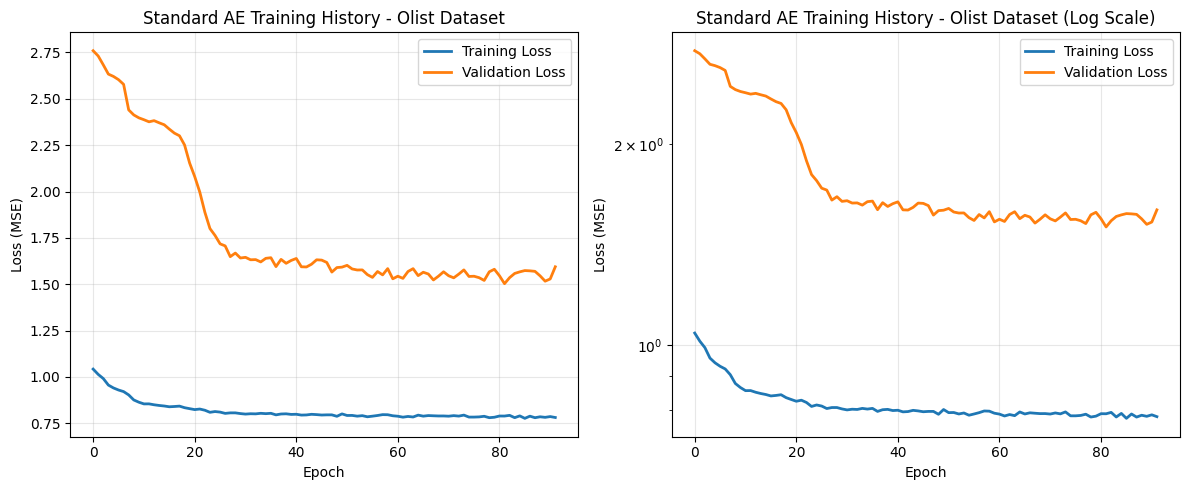

In [11]:
# ============================================================================
# CELL 12: Plot Training History - Standard AE Olist
# ============================================================================
print("\n" + "="*80)
print("PLOTTING TRAINING HISTORY - STANDARD AE OLIST")
print("="*80)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses_ae_olist, label='Training Loss', linewidth=2)
plt.plot(val_losses_ae_olist, label='Validation Loss', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Standard AE Training History - Olist Dataset')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(train_losses_ae_olist, label='Training Loss', linewidth=2)
plt.plot(val_losses_ae_olist, label='Validation Loss', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.title('Standard AE Training History - Olist Dataset (Log Scale)')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/figures/13_standard_ae_olist_training_history.png', dpi=300, bbox_inches='tight')
plt.show()


In [12]:
# ============================================================================
# GANTI CELL 15: Summary
# ============================================================================
print("\n" + "="*80)
print("BASELINE MODELS TRAINING SUMMARY")
print("="*80)

summary_data = {
    'Model': ['IF - Fraud', 'Standard AE - Fraud', 'IF - Olist', 'Standard AE - Olist'],
    'Type': ['Static', 'Static', 'Static', 'Static'],
    'Train Samples': [len(X_train_fraud_flat), len(X_train_fraud_flat),
                      len(X_train_olist_flat), len(X_train_olist_flat)],
    
    # --- PERUBAHAN DI SINI ---
    # Kita tidak lagi menghitung threshold di notebook ini.
    # Kita ubah string-nya untuk mencerminkan itu.
    'Threshold': ['Auto', 'Calculated in N5', 'Auto', 'Calculated in N5']
}

df_summary = pd.DataFrame(summary_data)
print("\n", df_summary.to_string(index=False))

print("\n" + "="*80)
print("BASELINE MODELS TRAINING COMPLETED!")
print("="*80)
print("\nNext steps:")
print("1. Run Notebook 5 for comprehensive evaluation")
print("2. Compare LSTM-AE vs Baseline models")
print("3. Generate final results tables")


BASELINE MODELS TRAINING SUMMARY

               Model   Type  Train Samples        Threshold
         IF - Fraud Static         198982             Auto
Standard AE - Fraud Static         198982 Calculated in N5
         IF - Olist Static          15205             Auto
Standard AE - Olist Static          15205 Calculated in N5

BASELINE MODELS TRAINING COMPLETED!

Next steps:
1. Run Notebook 5 for comprehensive evaluation
2. Compare LSTM-AE vs Baseline models
3. Generate final results tables
